# Project Python Foundations: FoodHub Data Analysis
# Marcelo Gomez

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [244]:
# Installing the libraries with the specified version.
#!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 -q --user

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [245]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [246]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [247]:
# Write your code here to read the data
df = pd.read_csv('....../foodhub_order.csv')

In [248]:
# Write your code here to view the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [249]:
# Write your code here
df.shape

(1898, 9)

#### Observations:
There are 1898 rows and 9 columns

### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [250]:
# Write your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


In [251]:
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

Observations:

There are: String, Float, and Integer.


it is interesting that the rating is string instead of Integer.<br>
We can see the raiting has 'Not given' value


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [252]:
# Write your code here
# creating a new column of raiting but as number. THe not a number is going to be NA
df['numeric_rating'] = pd.to_numeric(df['rating'], errors='coerce')
restaurants = df.groupby('restaurant_name')

# checking how many restaurants without ratings we have
# now that we have a 2 column df, we take the Series that represents the numeric rating and check if there is at least one Nan/null, returning True when a null is present.
null_ratings = restaurants['numeric_rating'].apply(lambda x: x.isnull().any())
# with the new series that has True and False, we sum the true part of it to see how many there are.
null_ratings.sum()

np.int64(134)

#### Observations:

There are 134 restaurants with at least one rating not given.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [253]:
# Write your code here
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time,numeric_rating
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000,1162.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749,4.344234
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637,0.741478
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000,3.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000,4.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000,5.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000,5.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000,5.000000


#### Observations:
the delivery_time has a mean of	24.161749 with the minimum time of 15 minutes and a maximum of 33 minutes

### **Question 5:** How many orders are not rated? [1 mark]

In [254]:
# Write the code here
# we take the df and create a series with True when the values is Nan/null.
without_rating = df['numeric_rating'].apply(pd.isnull)
# we count how many True we have
without_rating.sum()

np.int64(736)

#### Observations:

there are 736 orders without rating


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

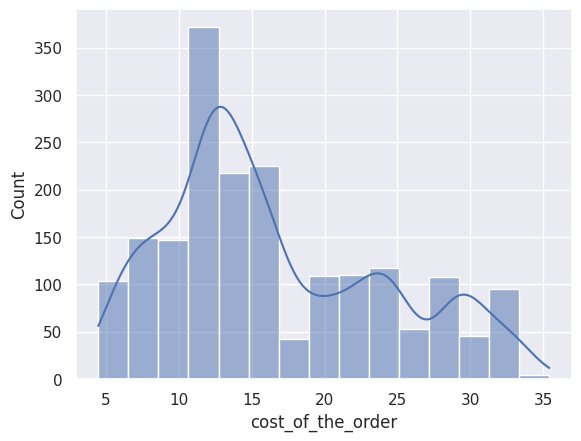

In [255]:
# Write the code here
sns.set_theme(style="darkgrid")
sns.histplot(df['cost_of_the_order'], kde=True, bins=15);

<Axes: xlabel='cost_of_the_order'>

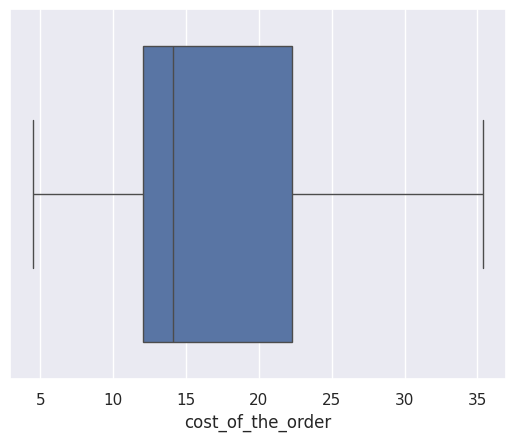

In [256]:
sns.boxplot(x=df['cost_of_the_order'])

**Observation** <br>
Most of the orders are between 12 and 23 and data is right/positive skewed

<Axes: xlabel='food_preparation_time', ylabel='Count'>

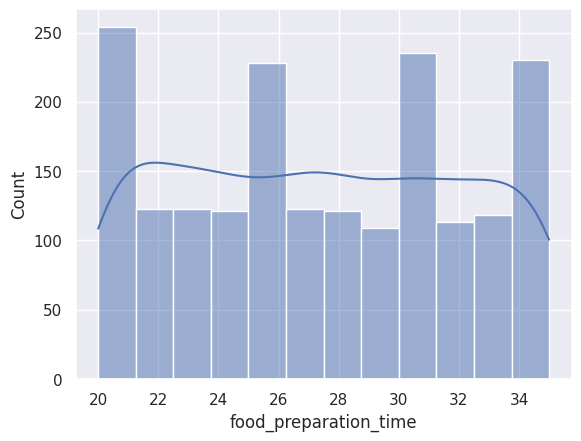

In [257]:
sns.histplot(df['food_preparation_time'], kde=True)

<Axes: xlabel='food_preparation_time'>

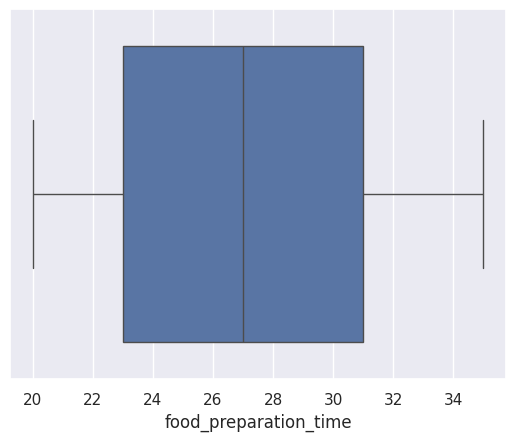

In [258]:
sns.boxplot(x=df['food_preparation_time'])

**Observation**:<br>
the 75% of the food is prepared in less than 31 minutes.<br>
The distribution looks to be very even.

<Axes: xlabel='delivery_time', ylabel='Count'>

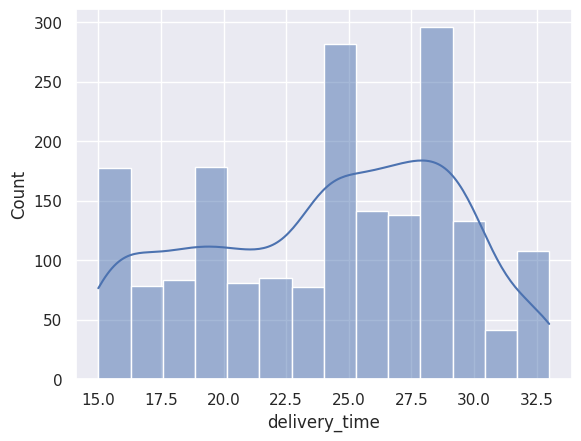

In [259]:
sns.histplot(df['delivery_time'], kde=True)

<Axes: xlabel='delivery_time'>

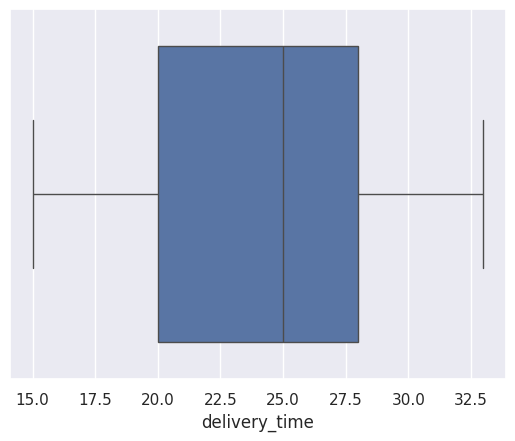

In [260]:
sns.boxplot(x=df['delivery_time'])

**Observations:**<br>
Data is left skewed, and 75% of the delivery time is 27.5 or less <br>
We can see that the majority of the delivery is done between 25 a 27.

<Axes: xlabel='numeric_rating', ylabel='Count'>

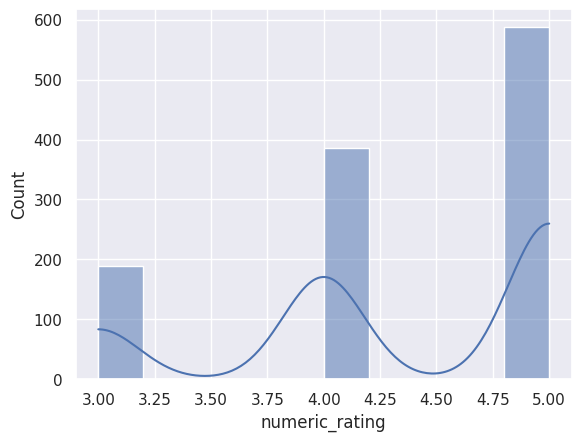

In [261]:
sns.histplot(df['numeric_rating'], kde=True, bins=10)

<Axes: xlabel='numeric_rating'>

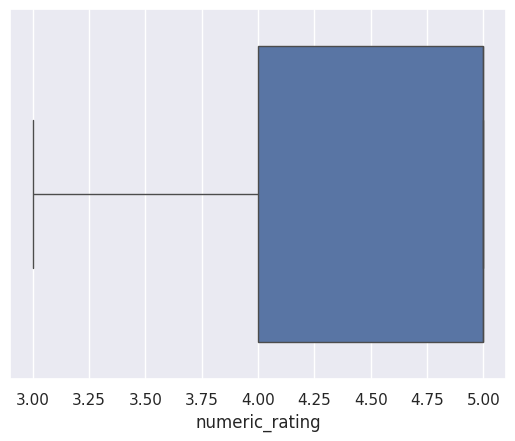

In [262]:
sns.boxplot(x=df['numeric_rating'])

**Observations:**<br>
It seems there were 3 to 5 ratings there were 3 to 5 rating if we remove those that are not ratings<br>
It is like most of the users rate the app as 5 stars<br>
It could be something the company is missing by having some not-rated trips<br>

<Axes: xlabel='day_of_the_week', ylabel='count'>

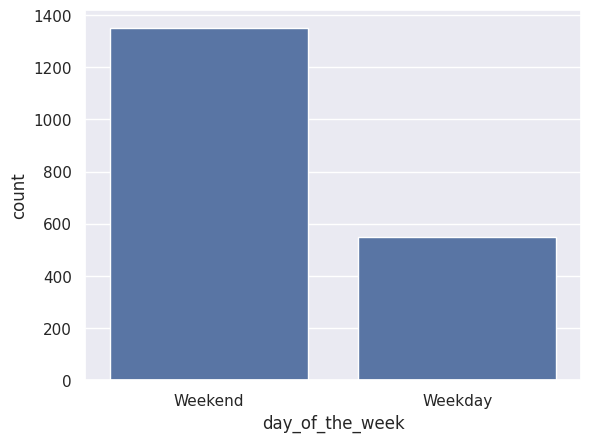

In [263]:
sns.countplot(x=df['day_of_the_week'])

<Axes: xlabel='cuisine_type', ylabel='count'>

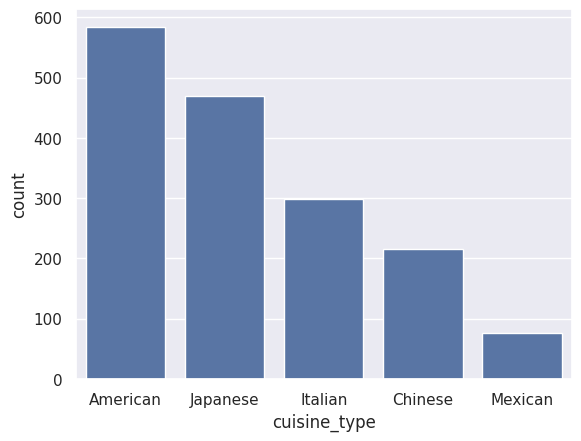

In [264]:

top_5_restaurant_type = df['cuisine_type'].value_counts().head(5)
sns.barplot(x=top_5_restaurant_type.index, y=top_5_restaurant_type )

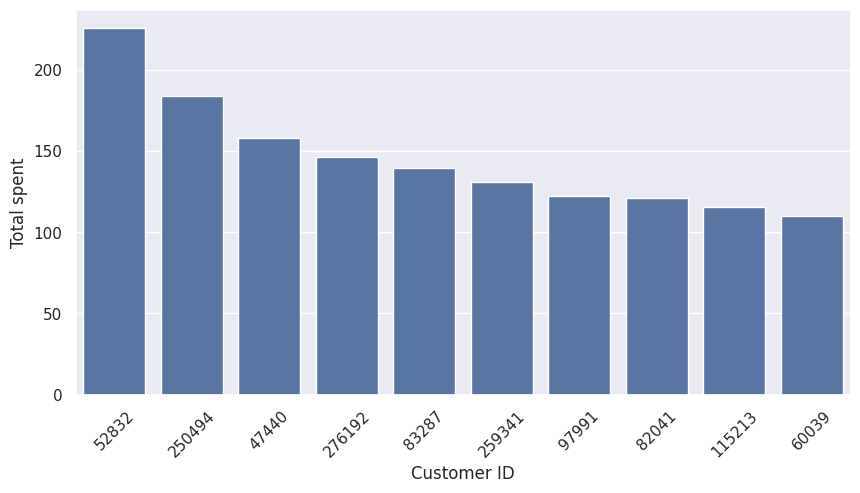

In [265]:
top_customers = df.groupby('customer_id')['cost_of_the_order'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_customers.index, y=top_customers.values, order=top_customers.index)
plt.xlabel("Customer ID")
plt.ylabel("Total spent")
plt.xticks(rotation=45)
plt.show()

**Observation**: <br>
We can see that american and japanese restaurants are the favorite restaurants, the majority of the sales are done during the weekend, and the user who has spent the most is the user 52832 with more than 200.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

/tmp/ipython-input-3782911526.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  top_5_plot.set_xticklabels(top_5_plot.get_xticklabels(), rotation=90)


<Axes: xlabel='restaurant_name', ylabel='order_id'>

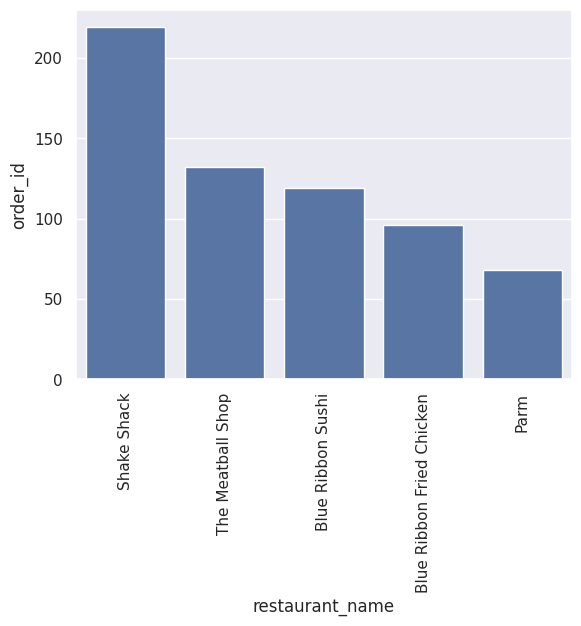

In [266]:
# Write the code here
# group by restaurant
restaraunt_x_order = df.groupby('restaurant_name')['order_id']
# count the orders
orders_count = restaraunt_x_order.count()
# get the top 5
top_5 = orders_count.sort_values(ascending=False).head(5)

top_5_plot = sns.barplot(x=top_5.index, y=top_5 )
top_5_plot.set_xticklabels(top_5_plot.get_xticklabels(), rotation=90)
top_5_plot

#### Observations:
The restaurants 'Shake Shack', 'The Meatball Shop', 'Blue Ribbon Sushi',
       'Blue Ribbon Fried Chicken', 'Parm' are the top 5 in terms of orders.

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

/tmp/ipython-input-935936721.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=90)


<Axes: xlabel='cuisine_type', ylabel='count'>

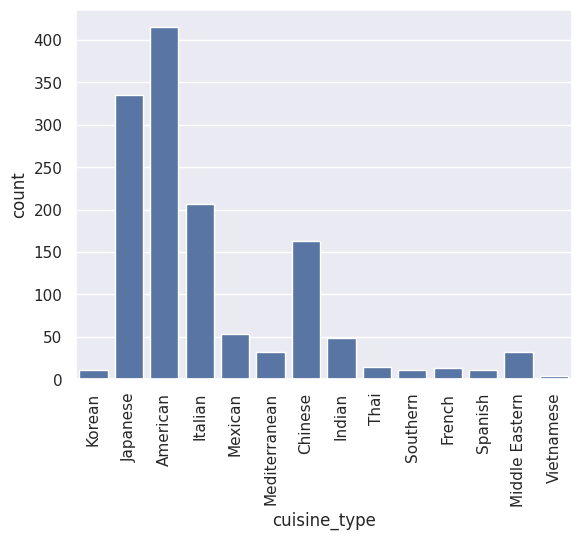

In [283]:
# Write the code here
#filtering the df by day of the week = Weekend
only_weekends = df[df['day_of_the_week'] == 'Weekend']
# grouping the df in a series with index cousine_type and value, the number of times that value apears
only_weekends['cuisine_type'].value_counts()
plot = sns.countplot(x=only_weekends['cuisine_type'])
plot.set_xticklabels(plot.get_xticklabels(), rotation=90)
plot

#### Observations:<br>
IT seem the American cousine is the most poplar on weekends


### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

<Axes: >

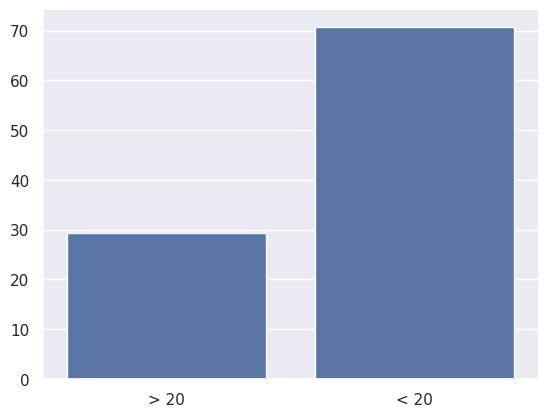

In [285]:
# Write the code here
# filtering the df by cost of the order more than 20
more_than_20 = df[df['cost_of_the_order'] > 20]
less_than_20 = df[df['cost_of_the_order'] < 20]
# getting the number of rows of the Series and using the rule of 3 to get the %
percentage_more_than_20 = more_than_20.shape[0] / df.shape[0] * 100
percentage_less_than_20 = less_than_20.shape[0] / df.shape[0] * 100

sns.barplot(x=['> 20', '< 20'], y=[percentage_more_than_20, percentage_less_than_20])


#### Observations: <br>
the porcentage of orders that costs more than 20 dollars is 29.24%

### **Question 10**: What is the mean order delivery time? [1 mark]

In [269]:
# Write the code here
delivery_time = df['delivery_time']
delivery_time.mean()

np.float64(24.161749209694417)

#### Observations: <br>
the Mean of the delivery time is a little more than 24 minutes

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

<Axes: xlabel='customer_id'>

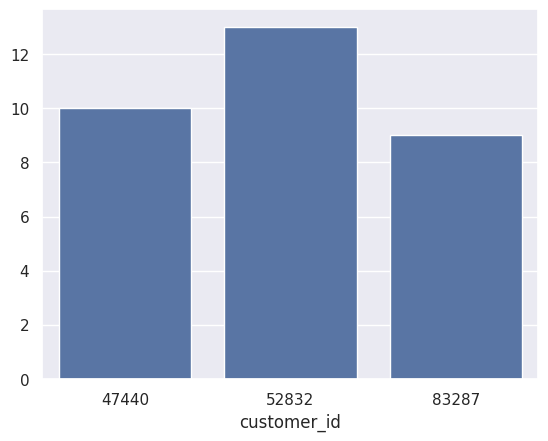

In [286]:
# Write the code here
# creating a Series that counts how many times a customer appears in the df
customers = df['customer_id'].value_counts()
# sorting the customers and geting the first 3 of them
top_3 = customers.sort_values(ascending=False).head(3)
# grouping the df by customer and order counting
customer_x_order = df.groupby('customer_id')['order_id']
# getting the orders of the top 3
top_3_customers_orders = customer_x_order.count()[top_3.index]
top_3_customers_orders

sns.barplot(x=top_3_customers_orders.index, y=top_3_customers_orders.values)

#### Observations:

Customers are 52832 with 13 orders, 47440 with 10 orders , and 83287 with 8 orders


### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


<Axes: >

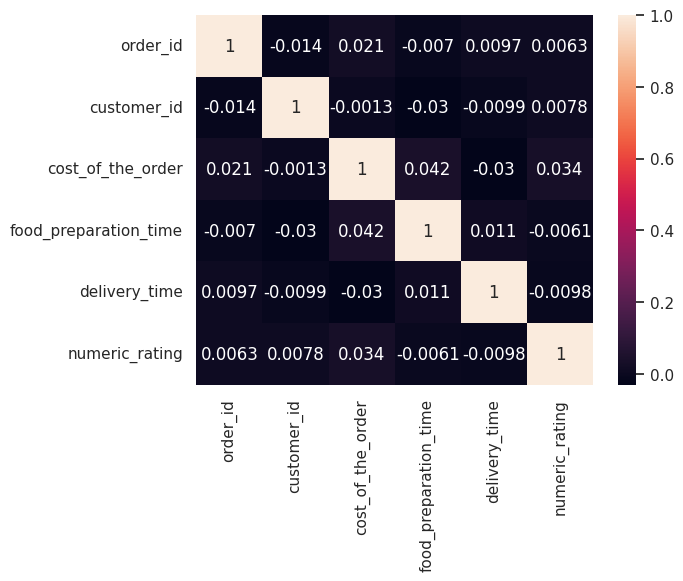

In [271]:
# Write the code here
numeric_cols = df.select_dtypes(include='number').corr()
sns.heatmap(numeric_cols, annot=True)

**Observation**:<br>
There is no significant relationship between the quantitative variables.

/tmp/ipython-input-3255581623.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cousine_x_cost_plot.set_xticklabels(cousine_x_cost_plot.get_xticklabels(), rotation=90)


<Axes: xlabel='cuisine_type'>

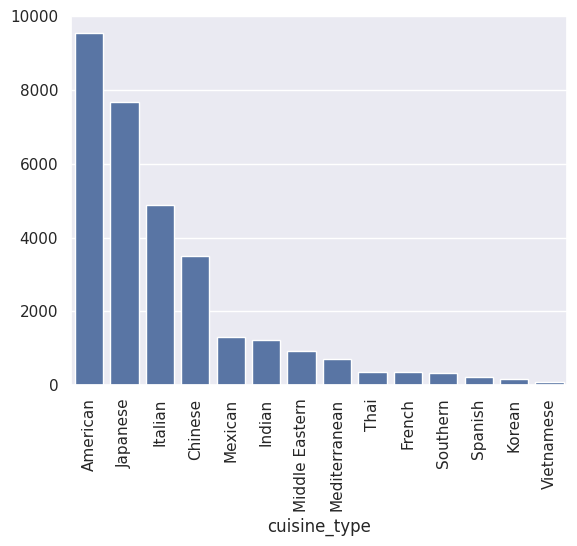

In [272]:
# grouping the cost of the orders by cuisine and suming the order costs then sorting it descending
cousine_x_cost  = df.groupby('cuisine_type')['cost_of_the_order'].sum().sort_values(ascending=False)
cousine_x_cost_plot = sns.barplot(x=cousine_x_cost.index, y=cousine_x_cost.values)
cousine_x_cost_plot.set_xticklabels(cousine_x_cost_plot.get_xticklabels(), rotation=90)
cousine_x_cost_plot


**Observation**<br>
The American, Japanese and Italian food are the ones that give more revenue

In [273]:
# creating a Series that groups restaurant names by cuisine type and counts how many times each cuisine type appears.
cuisine_type_x_restaurant_name = df.groupby('cuisine_type')['restaurant_name'].value_counts()
best_selers_by_type = cuisine_type_x_restaurant_name.groupby(level=0).head(1).sort_values(ascending=False)
best_selers_by_type

,,count
cuisine_type,restaurant_name,
American,Shake Shack,219
Japanese,Blue Ribbon Sushi,119
Italian,The Meatball Shop,112
Chinese,RedFarm Broadway,59
Indian,Tamarind TriBeCa,27
Mediterranean,Jack's Wife Freda,25
Mexican,Chipotle Mexican Grill $1.99 Delivery,23
Middle Eastern,Cafe Mogador,18
Southern,Hill Country Fried Chicken,14


**Observation**:<br>
We can see the more popular restaurants for each of the cuisine types.

<Axes: xlabel='day_of_the_week', ylabel='delivery_time'>

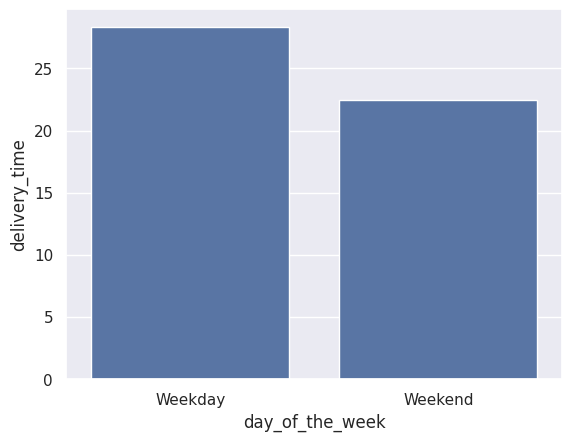

In [274]:
date_of_week_x_delivery_time = df.groupby('day_of_the_week')['delivery_time']

sns.barplot(data=date_of_week_x_delivery_time.mean())

**Observation**:<br>
On weekends, delivery is shorter.

<Axes: xlabel='day_of_the_week', ylabel='food_preparation_time'>

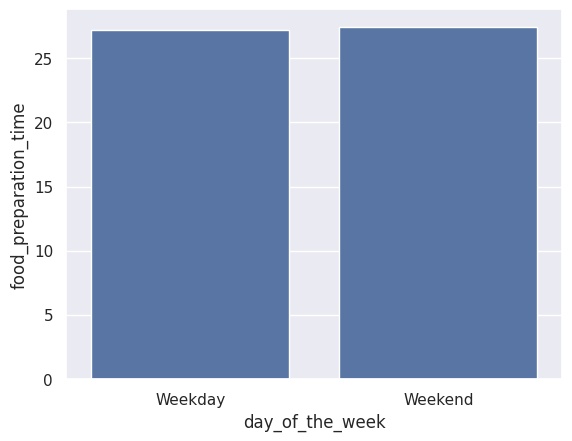

In [275]:
date_week_x_food_preparation_time = df.groupby('day_of_the_week')['food_preparation_time']
sns.barplot(data=date_week_x_food_preparation_time.mean())

/tmp/ipython-input-1662665064.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  boxplot.set_xticklabels(boxplot.get_xticklabels(), rotation=90)


<Axes: xlabel='cuisine_type', ylabel='cost_of_the_order'>

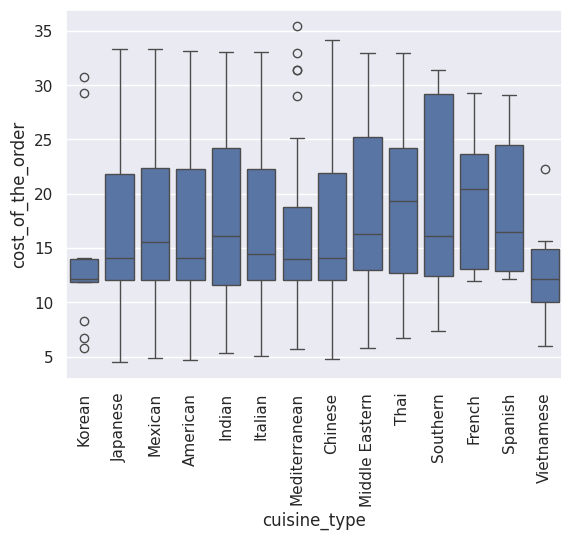

In [276]:
boxplot = sns.boxplot(
    x='cuisine_type',
    y='cost_of_the_order',
    data=df)
# rotating the labels 90 degrees
boxplot.set_xticklabels(boxplot.get_xticklabels(), rotation=90)
boxplot

**Observations**<br>
We can see customers of French cuisine trend to pay for expensive dishes. <br>
Vietnamese and Korean are the ones with less sales and with the cheapest order price.<br>
American orders are very variable.
and even when it has 50% in low price range it could have hig price orders.<br>
Thai food usually have expensive orders.


### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

/tmp/ipython-input-3084739373.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=90)


<Axes: xlabel='restaurant_name', ylabel='numeric_rating'>

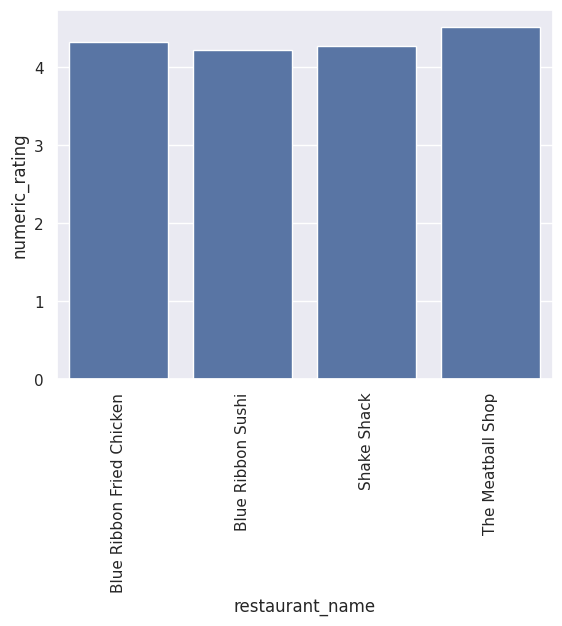

In [277]:
# Write the code here
# group the restaurant_names by their count
restaurant_x_count =  df.groupby('restaurant_name')['numeric_rating'].count()
# filtering restaurants with raiting count > 50
restaurant_more_50 = restaurant_x_count[restaurant_x_count > 50]
# getting the average of the raitings
rating_avg_x_restaurant = df.groupby('restaurant_name')['numeric_rating'].mean()
# filtering the average > 4
restaurant_avg_more_4 = rating_avg_x_restaurant[rating_avg_x_restaurant > 4]
# selecting the restaurants that can apply
can_apply_restaurants = restaurant_avg_more_4[restaurant_more_50.index]

plot = sns.barplot(x=can_apply_restaurants.index, y=can_apply_restaurants)
plot.set_xticklabels(plot.get_xticklabels(), rotation=90)
plot

#### Observations:
The restaurants that can apply for the promotional offer are: 'Blue Ribbon Fried Chicken', 'Blue Ribbon Sushi', 'Shake Shack', 'The Meatball Shop'


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

<Axes: xlabel='Costs', ylabel='Revenue'>

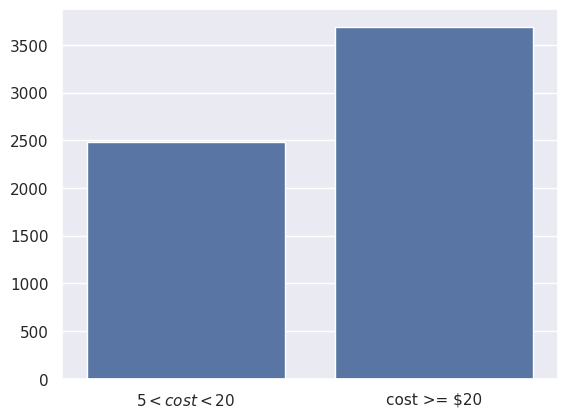

In [288]:
# Write the code here
# filter orders with orders more than 5 dollars
orders_more_than_5 = df[df['cost_of_the_order'] > 5]
# filter orders with more than 20 dollars
orders_more_than_20 = orders_more_than_5[orders_more_than_5['cost_of_the_order'] >= 20]
# filtering less than 20 dollars
orders_less_than_20 = orders_more_than_5[orders_more_than_5['cost_of_the_order'] < 20]
# the 15% and 25% of each
revenue_15 = orders_less_than_20['cost_of_the_order'] * 0.15
revenue_25 = orders_more_than_20['cost_of_the_order'] * 0.25
# sum the revenues
total_revenue = revenue_15.sum() + revenue_25.sum()
total_revenue

sns.barplot(x=['$5 < cost < $20', 'cost >= $20'], y=[revenue_15.sum(), revenue_25.sum()])
sbn

#### Observations:
The total revenue is 6166.303


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

<Axes: >

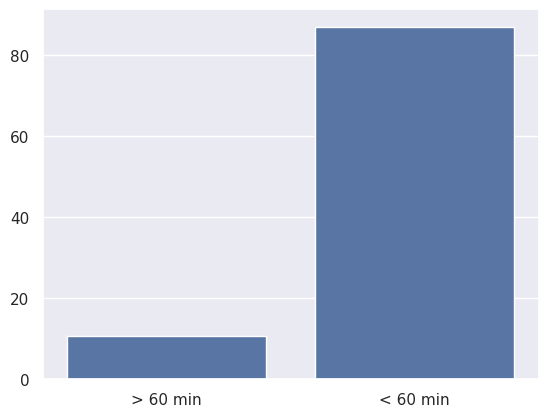

In [287]:
# Write the code here
# sum the delivery + preparation times
delivery_and_preparation = df['delivery_time'] + df['food_preparation_time']
# filter the time is more than 60
delivery_time_more_than_60 = delivery_and_preparation[delivery_and_preparation > 60]
delivery_time_less_than_60 = delivery_and_preparation[delivery_and_preparation < 60]

# getting the %
percentage_more_than_60 = delivery_time_more_than_60.shape[0] / df.shape[0] * 100
percentage_less_than_60 = delivery_time_less_than_60.shape[0] / df.shape[0] * 100


sns.barplot(x=['> 60 min', '< 60 min'], y=[percentage_more_than_60, percentage_less_than_60])


#### Observations:
A little more than 10% of the orders take more than 60 minutes to get delivered.

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

<Axes: xlabel='day_of_the_week'>

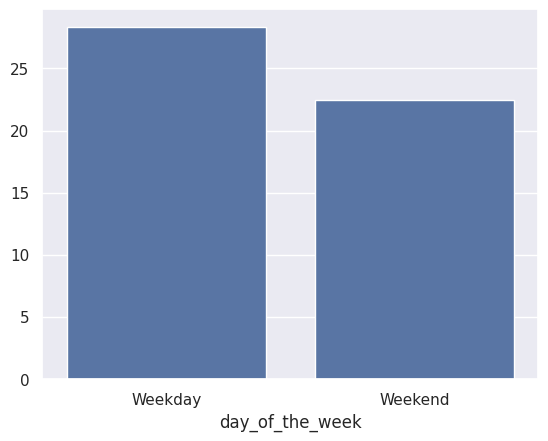

In [280]:
# Write the code here
# group the data in weekdays and weekends
grouped_by_day = df.groupby('day_of_the_week')['delivery_time']
# get the mean of each group
mean = grouped_by_day.mean()

sns.barplot(x=mean.index, y=mean.values)

#### Observations:
During the Weekdays, the mean of the delivery time is 28.340037 and during Weekend, it is 22.470022


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
*  American, Japanese, and Italian restaurants seem to be the favorites.
* On weekends, sales go up and deliveries are faster. Most orders are delivered in about 24 minutes.
* The company makes revenue of 6166.303 , with almost a third of orders costing more than $20.
* Some restaurants have high ratings and a lot of orders, so they are perfect for promotional offers.
* Vietnamese and Korean
* Orders without ratings, can be an issue

### Recommendations:

*  Create campaigns to encourage the buyers to buy in hige price restaurants like French, which gives more revenue to the company.
* Create campaigns that encourage more delivery partners during Weekdays or plan routes that take less time.
* Create a program in which the user gets a bonus by rating the app, so the app has fewer unrated orders.
* Try to have more delivery guys near restaurants of American, Japanese, and Italian because they usually have orders, and they are like the base of the revenue.
* Target support for Korean or Vietnamese restaurants to try to get more sales


---